# 02 - Lever Comparison, Phase 1 (single-seed scan)

Controlled ablation: start from the **vanilla 2017 baseline** and change **one lever at a time**.
Everything else is identical - same data, same budget (3000 iters), same **train-batch order**
and same **eval batches** across all configs - so any difference is due to the architecture lever.

Metric: **validation perplexity** (lower = better). Phase 1 uses 1 seed to find what's promising;
Phase 2 (next notebook) re-runs the top few with 3 seeds for trustworthy numbers.


In [1]:
%matplotlib inline
import os, math, time, csv
from contextlib import nullcontext
import torch
import matplotlib.pyplot as plt
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "cpu")

cands = ["../dataset/tinyshakespeare/input.txt", "dataset/tinyshakespeare/input.txt"]
path = next(p for p in cands if os.path.exists(p))
text = open(path, encoding="utf-8").read()
chars = sorted(set(text)); vocab = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
print(f"vocab={vocab}  train={len(train_data):,}  val={len(val_data):,}")

BLOCK, BATCH = 128, 64
def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix])
    y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()


device: cuda | NVIDIA GeForce RTX 3070
vocab=65  train=1,003,854  val=111,540


In [2]:
def train_config(overrides, seed=0, max_iters=3000, eval_iters=200,
                 lr=3e-4, warmup=150, min_lr=3e-5, wd=0.1):
    torch.manual_seed(seed)                                  # controls model init
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=4, n_head=4, n_embd=256,
                 dropout=0.1, **overrides)
    model = GPT(cfg).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=wd)
    train_gen = torch.Generator().manual_seed(7777 + seed)   # identical batch order across configs

    def get_lr(it):
        if it < warmup:
            return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))

    @torch.no_grad()
    def eval_val():
        model.eval()
        g = torch.Generator().manual_seed(4242)             # identical eval batches for ALL configs
        tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train()
        return tot / eval_iters

    t0 = time.time()
    for it in range(max_iters):
        for grp in opt.param_groups:
            grp["lr"] = get_lr(it)
        x, y = get_batch("train", train_gen)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    vl = eval_val()
    return {"val_loss": vl, "val_ppl": math.exp(vl), "params_M": count_params(model) / 1e6,
            "sec": time.time() - t0}

print("train_config ready")


train_config ready


In [3]:
# one change per config, vs the vanilla 2017 baseline
SWEEP = {
    "baseline":   {},
    "learned_pe": {"pos_encoding": "learned"},
    "rope":       {"pos_encoding": "rope"},
    "alibi":      {"pos_encoding": "alibi"},
    "no_pe":      {"pos_encoding": "none"},
    "pre_ln":     {"norm_placement": "pre"},
    "rmsnorm":    {"norm_type": "rmsnorm"},
    "gelu":       {"activation": "gelu"},
    "swiglu":     {"activation": "swiglu"},
    "gqa_kv2":    {"attention": "gqa", "n_kv_head": 2},
    "sliding64":  {"attention": "sliding", "window_size": 64},
}
print(len(SWEEP), "configs to run")


11 configs to run


In [4]:
# === PHASE 1: single-seed scan (3000 iters each, ~90s/run) ===
os.makedirs("../results", exist_ok=True)
csv_path = "../results/sweep_phase1.csv"
with open(csv_path, "w", newline="") as f:
    csv.writer(f).writerow(["config", "val_loss", "val_ppl", "params_M", "sec"])

results = {}
t_start = time.time()
for name, over in SWEEP.items():
    r = train_config(over, seed=0, max_iters=3000)
    results[name] = r
    with open(csv_path, "a", newline="") as f:   # append incrementally (crash-safe)
        csv.writer(f).writerow([name, f"{r['val_loss']:.4f}", f"{r['val_ppl']:.4f}",
                                f"{r['params_M']:.3f}", f"{r['sec']:.1f}"])
    print(f"{name:11s} val_ppl {r['val_ppl']:6.3f} | val_loss {r['val_loss']:.4f} | "
          f"{r['params_M']:.2f}M | {r['sec']:.0f}s", flush=True)
print(f"\nPHASE 1 DONE in {(time.time()-t_start)/60:.1f} min")


baseline    val_ppl  5.367 | val_loss 1.6803 | 3.18M | 75s


learned_pe  val_ppl  5.769 | val_loss 1.7525 | 3.21M | 74s


rope        val_ppl  5.074 | val_loss 1.6242 | 3.18M | 89s


alibi       val_ppl  5.562 | val_loss 1.7159 | 3.18M | 75s


no_pe       val_ppl  6.621 | val_loss 1.8902 | 3.18M | 73s


pre_ln      val_ppl  5.259 | val_loss 1.6600 | 3.18M | 76s


... (2 outputs left out)

swiglu      val_ppl  5.140 | val_loss 1.6370 | 3.18M | 83s


gqa_kv2     val_ppl  5.453 | val_loss 1.6961 | 2.91M | 70s


sliding64   val_ppl  5.344 | val_loss 1.6760 | 3.18M | 69s



PHASE 1 DONE in 14.1 min


config        val_ppl  vs baseline
----------------------------------
rope            5.074       -5.46%
swiglu          5.140       -4.24%
pre_ln          5.259       -2.01%
sliding64       5.344       -0.44%
baseline        5.367       +0.00%  <-- baseline
rmsnorm         5.384       +0.32%
gelu            5.433       +1.22%
gqa_kv2         5.453       +1.59%
alibi           5.562       +3.63%
learned_pe      5.769       +7.49%
no_pe           6.621      +23.35%


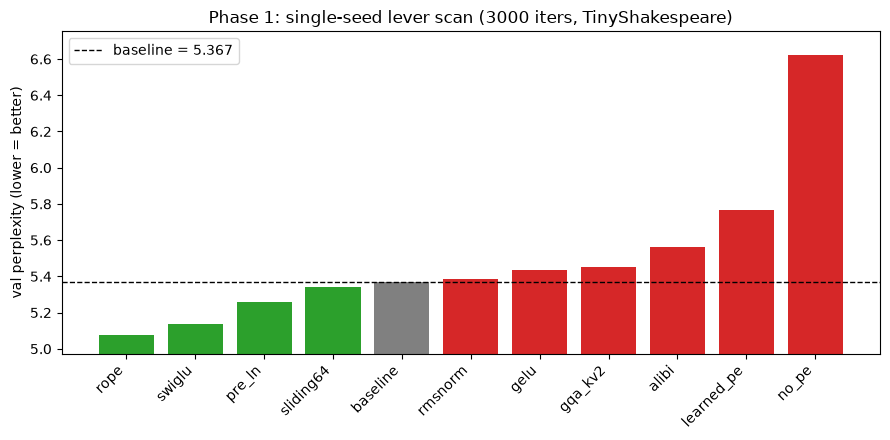

In [5]:
# results table + chart (vs baseline)
base = results["baseline"]["val_ppl"]
ranked = sorted(results.items(), key=lambda kv: kv[1]["val_ppl"])
print(f"{'config':12s} {'val_ppl':>8s} {'vs baseline':>12s}")
print("-" * 34)
for name, r in ranked:
    delta = 100 * (r["val_ppl"] - base) / base
    tag = "  <-- baseline" if name == "baseline" else ""
    print(f"{name:12s} {r['val_ppl']:8.3f} {delta:+11.2f}%{tag}")

names = [k for k, _ in ranked]
ppls = [v["val_ppl"] for _, v in ranked]
colors = ["gray" if k == "baseline" else ("tab:green" if v["val_ppl"] < base else "tab:red")
          for k, v in ranked]
plt.figure(figsize=(9, 4.5))
plt.bar(names, ppls, color=colors)
plt.axhline(base, ls="--", c="black", lw=1, label=f"baseline = {base:.3f}")
plt.ylabel("val perplexity (lower = better)")
plt.title("Phase 1: single-seed lever scan (3000 iters, TinyShakespeare)")
plt.xticks(rotation=45, ha="right"); plt.legend()
plt.ylim(min(ppls) * 0.98, max(ppls) * 1.02)
plt.tight_layout(); plt.savefig("../results/sweep_phase1.png", dpi=120); plt.show()


## Reading this

Green bars beat the baseline; red are worse. **But 1 seed is noisy** - a small green margin
could be luck. So in **Phase 2** we take the top handful (plus the baseline) and re-run each
with **3 seeds**, reporting mean +/- std. Only effects that survive that are real candidates
for the paper.
